In [1]:
using QuantumCollocation
using NamedTrajectories
using TrajectoryIndexingUtils

using CairoMakie
using DelimitedFiles
using Distributions
using LinearAlgebra
using SparseArrays
pathof(QuantumCollocation)

"/home/andy/Documents/Research/JuliaPackages/StealthPICO/src/QuantumCollocation.jl"

In [2]:
# Operators 
const n_levels = 2
const a⁺ = create(n_levels)
const a⁻ = annihilate(n_levels)

const H_ops = Dict(
        "X" => a⁻ + a⁺,
        "Y" => -im * (a⁻ - a⁺),
        "Z" => I - 2 * a⁺ * a⁻,
)

# Time
T = 45
Δt = 2/9

# Basic gates
I_gate = Matrix{ComplexF64}(I, 2, 2)
X_gate = GATES[:X]
SX_gate = sqrt(GATES[:X])

2×2 Matrix{ComplexF64}:
 0.5+0.5im  0.5-0.5im
 0.5-0.5im  0.5+0.5im

In [24]:
case = "5qubits"
if case == "4qubits"
    neighbors = [join([(i == j || i == mod(j, 4) + 1) ? "Z" : "I" for i in 1:4]) for j in 1:4]
    dephasing = [join([(i == j) ? "Z" : "I" for i in 1:4]) for j in 1:4]
    crosstalk_labels = vcat(neighbors, dephasing)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:4]) for j in 1:4]

    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate])
elseif case == "6qubits"
    neighbors = [join([(i == j || i == mod(j, 6) + 1) ? "Z" : "I" for i in 1:6]) for j in 1:6]
    diagonals = [join([(i == j || i == mod(j, 6) + 3) ? "Z" : "I" for i in 1:6]) for j in 1:3]
    # Dephasing unnecessary because of identity
    # dephasing = [join([(i == j) ? "Z" : "I" for i in 1:6]) for j in 1:6]
    crosstalk_labels = vcat(neighbors, diagonals)
    H_crosstalk = sum(kron_from_dict(n, H_ops) for n in crosstalk_labels)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:6]) for j in 1:6]
    
    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate, I_gate, I_gate])

elseif case == "5qubits"
    # don't loop back around
    neighbors = [join([(i == j || i == mod(j, 5) + 1) ? "Z" : "I" for i in 1:5]) for j in 1:4]
    diagonals = [join([(i == j || i == mod(j, 5) + 3) ? "Z" : "I" for i in 1:5]) for j in 1:2]
    # technically only need odds (evens play next to shaped identity)
    dephasing = [join([(i == j) ? "Z" : "I" for i in 1:5]) for j in [1,3,5]]
    crosstalk_labels = vcat(neighbors, diagonals, dephasing)

    H_controls_names = [join([i == j ? "X" : "I" for i in 1:5]) for j in 1:5]

    U_goal = reduce(kron, [X_gate, X_gate, SX_gate, SX_gate, I_gate])
end;

In [25]:
H_controls = [kron_from_dict(n, H_ops) for n in H_controls_names]
H_drift = zeros(n_levels^length(H_controls), n_levels^length(H_controls))
H_crosstalk = sum(kron_from_dict(n, H_ops) for n in crosstalk_labels)
;

In [26]:
@views function infidelity_robustness(Hₑ::AbstractMatrix, p::QuantumControlProblem)
    Z⃗ = vec(p.trajectory.data)
    Z = p.trajectory
    return InfidelityRobustnessObjective(Hₑ, Z).L(Z⃗, Z)
end

infidelity_robustness (generic function with 1 method)

# Original control problem

In [28]:
# Hopefully you don't need this... depends how much memory the problem takes
ops = Options()
# ops.mumps_mem_percent = 5

prob = UnitarySmoothPulseProblem(
    H_drift,
    H_controls,
    U_goal,
    T,
    Δt;
    a_guess=(π/2/T/Δt) * ones((length(H_controls), T)),
    timesteps_all_equal=true,
    free_time=false,
    hessian_approximation=true,
    pade_order=20,
    R=10.,
    R_dda=5.,
    ipopt_options=ops
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB


applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a


applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [33]:
solve!(prob; max_iter=60)

println("Fidelity: ", unitary_fidelity(prob))
println("Crosstalk robustness: ", infidelity_robustness(H_crosstalk, prob))


This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        0
        inequality constraints with only lower bounds:        0
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  9.5215701e-01 2.63e-04 5.59e-02   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  1.0121959e+00 1.53e-04 3.14e+00 -11.0 5.59e-02    -  1.00e+00 1.00e+00h  1


   2  9.4622943e-01 6.43e-06 2.19e+00 -11.0 3.62e-02    -  1.00e+00 1.00e+00h  1


   3  9.4712571e-01 1.43e-06 2.40e-01 -11.0 7.05e-03    -  1.00e+00 1.00e+00h  1


   4  9.3074246e-01 9.97e-06 7.25e-01 -11.0 1.14e-01    -  1.00e+00 1.00e+00h  1


   5  9.2407342e-01 2.05e-05 1.97e-01 -11.0 5.91e-02    -  1.00e+00 1.00e+00h  1


... (12 outputs left out)

  18  9.1833633e-01 1.44e-07 2.69e-01 -11.0 7.10e-02    -  1.00e+00 1.00e+00F  1


  19  9.2275327e-01 2.29e-08 3.58e-01 -11.0 9.34e-02    -  1.00e+00 1.00e+00H  1


iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
  20  9.0940300e-01 2.38e-05 5.86e-02 -11.0 6.14e-02    -  1.00e+00 1.00e+00f  1



Number of Iterations....: 20

                                   (scaled)                 (unscaled)
Objective...............:   9.0940300305932542e-01    9.0940300305932542e-01
Dual infeasibility......:   5.8556200714293564e-02    5.8556200714293564e-02
Constraint violation....:   2.3780976830201084e-05    2.3780976830201084e-05
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   0.0000000000000000e+00    0.0000000000000000e+00
Overall NLP error.......:   5.8556200714293564e-02    5.8556200714293564e-02


Number of objective function evaluations             = 45
Number of objective gradient evaluations             = 21
Number of equality constraint evaluations            = 45
Number of inequality constraint evaluations          = 0
Number of equality constraint Jacobian evaluations   = 21
Number of inequality constraint Jacobian evaluations = 0
Number of Lagrangian Hessian evaluations             = 0
Total seconds in IPOPT         

In [34]:
function plot_control(
    ts::AbstractVector, 
    as::Union{Nothing, AbstractMatrix}=nothing,
    das::Union{Nothing, AbstractMatrix}=nothing,
    ddas::Union{Nothing, AbstractMatrix}=nothing,
)
    # plot(prob.trajectory; comps=[:a, :da, :dda])
    f = Figure(resolution=(800, 600))
    colors = [:red, :green, :blue, :orange, :purple, :yellow, :black]

    if !isnothing(as)
        ax1 = Axis(f[1, 1])
        for i in 1:size(as, 1)
            lines!(ax1, ts, as[i, :]; color=colors[i])
        end
    end
    if !isnothing(das)
        ax2 = Axis(f[2, 1])
        for i in 1:size(as, 1)
            lines!(ax2, ts, das[i, :]; color=colors[i])
        end
    end
    if !isnothing(ddas)
        ax3 = Axis(f[3, 1])
        for i in 1:size(as, 1)
            lines!(ax3, ts, ddas[i, :]; color=colors[i])
        end
    end
    return f
end

function plot_control(prob::QuantumControlProblem)
    ts = accumulate(+, timesteps(prob.trajectory))
    as = prob.trajectory[:a]
    das = prob.trajectory[:da]
    ddas = prob.trajectory[:dda]
    return plot_control(ts, as, das, ddas)
    f = Figure(resolution=(800, 600))
end



plot_control (generic function with 5 methods)

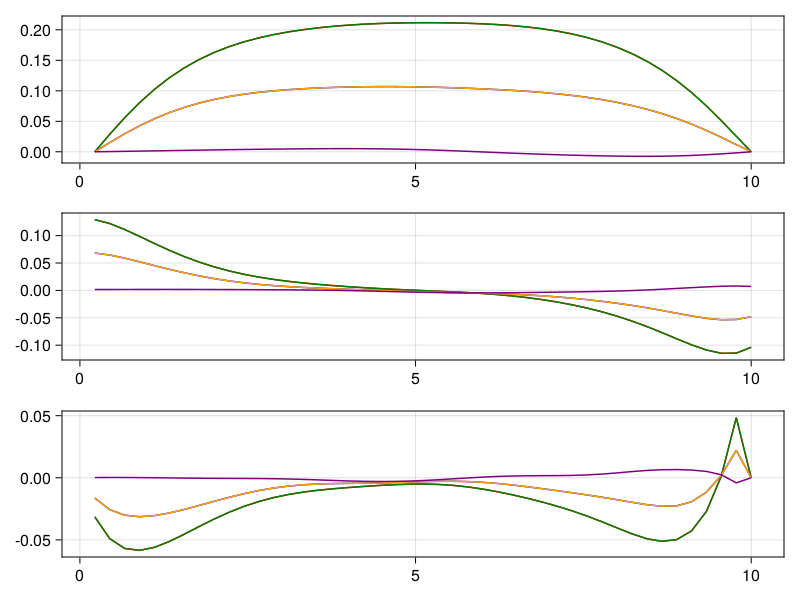

In [35]:
plot_control(prob)

In [36]:
println("max(a): ", maximum(prob.trajectory[:a]))
println("max(dda): ", maximum(prob.trajectory[:dda]))

max(a): 0.21170941291299253
max(dda): 0.04842611056214399


In [37]:
save("saved-pulses/single_qubit_gateset_default.jld2", prob.trajectory)

In [38]:
writedlm("saved-pulses/a_single_qubit_gateset_default.csv", prob.trajectory[:a], ",")

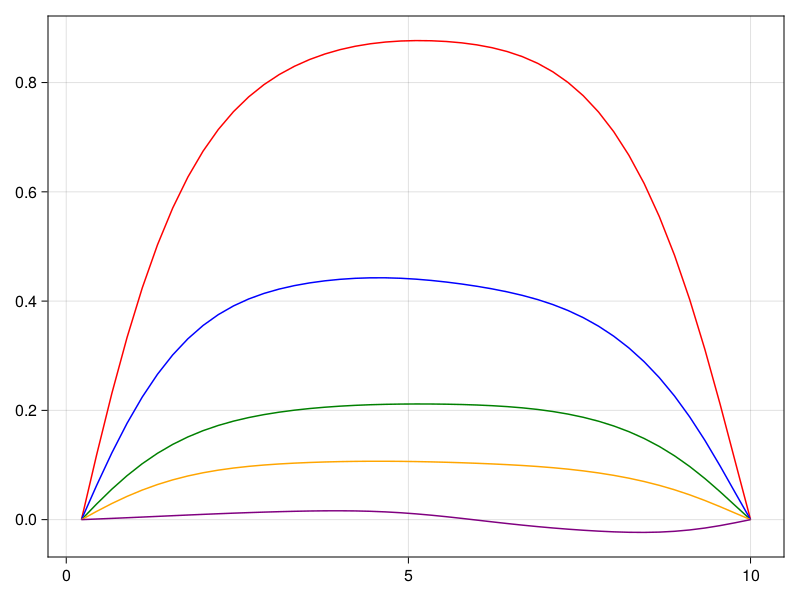

In [40]:
plot_control(accumulate(+, timesteps(prob.trajectory)), [1 + π, 1, 1 + π, 1, π] .* prob.trajectory[:a])

In [41]:
function random_a_guess(traj::NamedTrajectory)
    # Positive (symmetric) upper bounds
    a_bounds = traj.bounds[:a][2]

    a_dists = [Uniform(
        -(a_bounds[i] == Inf ? 1.0 : a_bounds[i]),
        (a_bounds[i] == Inf ? 1.0 : a_bounds[i])
    ) for i = 1:traj.dims[:a]]

    a = hcat([
        zeros(traj.dims[:a]),
        vcat([rand(a_dists[i], 1, T - 2) for i = 1:traj.dims[:a]]...),
        zeros(traj.dims[:a])
    ]...)
    return a
end

random_a_guess (generic function with 1 method)

# Offset initial controls with amplitude contraint

Note: The option 1, where we don't stagger, led to pulses that were not good. The initialization via the stagger is important?

In [42]:
trajectory = copy(prob.trajectory)
# Need random initial conditions to avoid local minima

# Option 1:
# ----------------
# Don't stagger! Try to use the same order of magnitude as the initial gates.
# update!(trajectory, :a, [π/2/10 , π/2/10, π/4/10, π/4/10] .* random_a_guess(trajectory))
# update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)

# Option 2:
# ----------------
# Stagger as in the plot above
update!(trajectory, :a, [1 + π, 1, 1 + π, 1, π] .* prob.trajectory[:a])
update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)

parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += Objective(parameters[:objective_terms][1])
objective += QuadraticRegularizer(:dda, trajectory, 1e-3)
objective += QuadraticRegularizer(:a, trajectory, 1e-6)

update_bound!(trajectory, :a, 1.0)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_1 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9, 
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [43]:
solve!(rob_prob_1; max_iter=100)

println("Fidelity: ", unitary_fidelity(rob_prob_1))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_1))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:      215
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  8.3984445e+01 2.17e+00 1.22e-01   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  8.4159961e+01 2.14e+00 9.39e+01  -1.3 1.98e+00    -  9.89e-01 1.07e-02h  1


   2  8.3581799e+01 2.13e+00 9.55e+03  -1.2 1.55e+01    -  7.57e-01 7.83e-03h  1


   3  5.6642219e+01 1.35e+00 8.12e+03  -1.0 1.56e+01    -  1.00e+00 3.58e-01h  1


   4  5.1354749e+01 1.19e+00 4.96e+03  -0.1 1.10e+01    -  1.00e+00 1.12e-01h  1


   5  4.7901618e+01 1.09e+00 4.25e+03   0.4 1.95e+01    -  1.00e+00 8.21e-02h  1


... (91 outputs left out)

  97  1.3053468e-03 4.50e-04 1.56e+00  -4.1 2.44e-01    -  1.00e+00 1.00e+00h  1


  98  1.3786434e-03 1.22e-03 1.56e+00  -4.0 9.59e-01    -  1.00e+00 5.00e-01h  2


  99  1.1982239e-03 7.97e-04 1.56e+00  -4.1 2.82e-01    -  1.00e+00 1.00e+00h  1


iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
 100  1.2297941e-03 2.36e-04 1.56e+00  -4.0 1.32e-01  -4.0 1.00e+00 1.00e+00h  1

Number of Iterations....: 100

                                   (scaled)                 (unscaled)
Objective...............:   1.2297940500635373e-03    1.2297940500635373e-03
Dual infeasibility......:   1.5627367397512837e+00    1.5627367397512837e+00
Constraint violation....:   2.3555937069652533e-04    2.3555937069652533e-04
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.0047588572663516e-04    1.0047588572663516e-04
Overall NLP error.......:   1.5627367397512837e+00    1.5627367397512837e+00


Number of objective function evaluations             = 185
Number of objective gradient evaluations             = 101
Number of equality constraint evaluations            = 185
Number of inequality constraint evaluations          = 185
Number of equality constraint Jacob

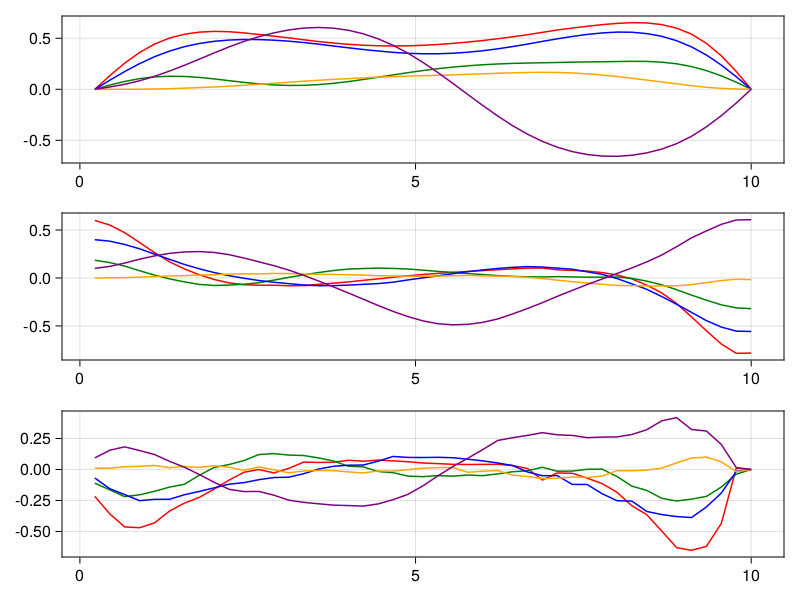

In [44]:
plot_control(rob_prob_1)

In [45]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-5)
objective += QuadraticRegularizer(:a, trajectory, 1e-5)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_2 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [55]:
solve!(rob_prob_2; max_iter=9) # 75

println("Fidelity: ", unitary_fidelity(rob_prob_2))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_2))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  4.7691432e-05 5.66e-04 3.04e-04   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  4.7561311e-05 1.22e-04 2.63e-03  -4.0 1.03e-02    -  1.00e+00 9.64e-01h  1


   2  4.8012981e-05 6.29e-05 2.87e-04  -4.0 1.68e-01    -  1.00e+00 1.00e+00h  1


   3  4.7343958e-05 2.67e-05 1.93e-04  -5.2 1.14e-01    -  1.00e+00 1.00e+00h  1


   4  5.6149665e-05 1.15e-03 7.73e-03  -4.0 8.48e-01    -  1.00e+00 1.00e+00h  1


   5  4.8830089e-05 3.65e-04 2.11e-03  -3.5 3.82e-01    -  1.00e+00 1.00e+00h  1


... (2 outputs left out)

   8  4.6838142e-05 1.49e-06 1.18e-06  -7.9 5.29e-03    -  1.00e+00 1.00e+00h  1


   9  4.4831821e-05 7.82e-05 4.00e-03  -4.0 6.36e-02    -  1.00e+00 1.00e+00h  1



Number of Iterations....: 9

                                   (scaled)                 (unscaled)
Objective...............:   4.4831820658900595e-05    4.4831820658900595e-05
Dual infeasibility......:   3.9954006819182594e-03    3.9954006819182594e-03
Constraint violation....:   7.8163737229353103e-05    7.8163737229353103e-05
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.2633249326172985e-04    1.2633249326172985e-04
Overall NLP error.......:   3.9954006819182594e-03    3.9954006819182594e-03


Number of objective function evaluations             = 10
Number of objective gradient evaluations             = 10
Number of equality constraint evaluations            = 10
Number of inequality constraint evaluations          = 10
Number of equality constraint Jacobian evaluations   = 10
Number of inequality constraint Jacobian evaluations = 10
Number of Lagrangian Hessian evaluations             = 0
Total seconds in IPOPT        

1.9084606456898076e-5


In [47]:
println("max(a): ", maximum(rob_prob_2.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_2.trajectory[:dda]))

max(a): 0.9118863158213467
max(dda): 1.2282583856092786


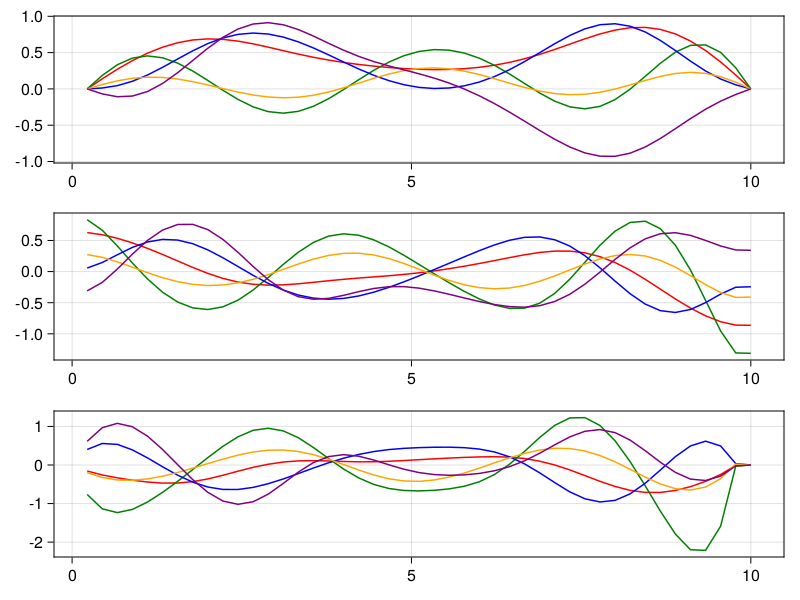

In [48]:
plot_control(rob_prob_2)

In [49]:
save("saved-pulses/single_qubit_gateset_R1e-5.jld2", rob_prob_2.trajectory)

In [50]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-5.csv", rob_prob_2.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, tighten R's

In [56]:
trajectory = copy(rob_prob_1.trajectory)
# Need random initial conditions to avoid local minima
# update!(trajectory, :a, random_a_guess(trajectory))
# update!(trajectory, :Ũ⃗, 2 * rand(trajectory.dims[:Ũ⃗], T) .- 1)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-3)
objective += QuadraticRegularizer(:a, trajectory, 1e-3)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-3

rob_prob_3 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [57]:
solve!(rob_prob_3; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_3))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_3))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.9014474e-03 2.36e-04 4.53e-04   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  1.9013178e-03 1.25e-03 2.14e-02  -4.0 1.15e-02    -  1.00e+00 8.63e-01h  1


   2  1.8755492e-03 8.40e-05 1.96e-03  -4.0 3.72e-02    -  1.00e+00 1.00e+00h  1


   3  1.8564581e-03 5.13e-05 6.36e-04  -4.0 6.39e-02    -  1.00e+00 1.00e+00h  1


   4  1.8215794e-03 3.27e-05 5.83e-04  -4.0 3.22e-02    -  1.00e+00 1.00e+00h  1


   5  1.8180986e-03 1.35e-05 4.96e-04  -4.0 2.04e-02    -  1.00e+00 1.00e+00h  1


... (66 outputs left out)

  72  1.4433732e-03 7.24e-08 1.11e-06  -4.0 1.26e-03    -  1.00e+00 1.00e+00h  1


  73  1.4433282e-03 8.04e-10 9.30e-07  -4.0 2.07e-04    -  1.00e+00 1.00e+00h  1


  74  1.4433282e-03 4.05e-14 1.04e-06  -4.0 4.12e-04    -  1.00e+00 1.00e+00H  1


  75  1.4431464e-03 8.24e-08 6.73e-06  -4.0 1.76e-02    -  1.00e+00 2.50e-01h  3

Number of Iterations....: 75

                                   (scaled)                 (unscaled)
Objective...............:   1.4431464300620838e-03    1.4431464300620838e-03
Dual infeasibility......:   6.7271049627690148e-06    6.7271049627690148e-06
Constraint violation....:   8.2423988412294591e-08    8.2423988412294591e-08
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.0053154851225221e-04    1.0053154851225221e-04
Overall NLP error.......:   6.7271049627690148e-06    6.7271049627690148e-06


Number of objective function evaluations             = 107
Number of objective gradient evaluations             = 76
Number of equality constraint evaluations            = 107
Number of inequality constraint evaluations          = 107
Number of equality constraint Jacobian evaluations   = 76
Number of inequality constraint Jacobian evaluations = 76
Nu

In [58]:
println("max(a): ", maximum(rob_prob_3.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_3.trajectory[:dda]))

max(a): 0.7364906361006086
max(dda): 0.4156847872668531


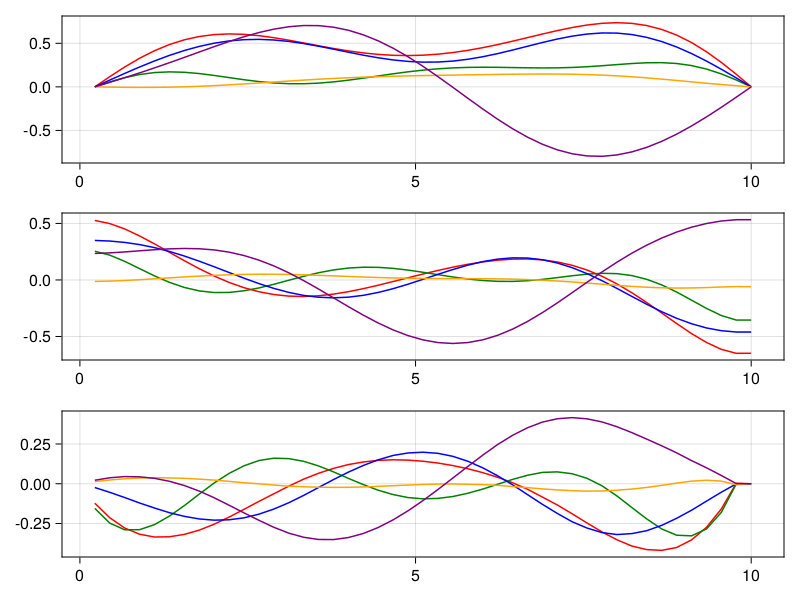

In [59]:
plot_control(rob_prob_3)

In [60]:
save("saved-pulses/single_qubit_gateset_R1e-3.jld2", rob_prob_3.trajectory)

In [61]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-3.csv", rob_prob_3.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, loosen R

In [62]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-6)
objective += QuadraticRegularizer(:a, trajectory, 1e-6)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_4 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [63]:
solve!(rob_prob_4; max_iter=100)

println("Fidelity: ", unitary_fidelity(rob_prob_4))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_4))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  1.0059467e-03 2.36e-04 4.67e-04   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  1.0056537e-03 1.25e-03 2.14e-02  -4.0 1.15e-02    -  1.00e+00 8.63e-01h  1


   2  9.5716454e-04 8.56e-05 1.91e-03  -4.0 4.69e-02    -  1.00e+00 1.00e+00h  1


   3  9.1919859e-04 5.53e-05 5.56e-04  -4.0 7.40e-02    -  1.00e+00 1.00e+00h  1


   4  8.4977263e-04 5.52e-05 8.31e-04  -4.0 4.99e-02    -  1.00e+00 1.00e+00h  1


   5  8.4343506e-04 4.04e-05 9.14e-04  -4.0 3.11e-02    -  1.00e+00 1.00e+00h  1


... (92 outputs left out)

  98  1.9918011e-05 2.42e-04 1.01e-04  -5.4 7.66e-02    -  1.00e+00 1.00e+00h  1


  99  1.7846034e-05 1.63e-04 3.56e-04  -4.0 8.13e-02    -  1.00e+00 1.00e+00h  1


iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
 100  1.9470889e-05 1.31e-04 2.86e-04  -4.0 7.31e-02    -  1.00e+00 1.00e+00h  1



Number of Iterations....: 100

                                   (scaled)                 (unscaled)
Objective...............:   1.9470888861740059e-05    1.9470888861740059e-05
Dual infeasibility......:   2.8550365850617628e-04    2.8550365850617628e-04
Constraint violation....:   1.3054755090013970e-04    1.3054755090013970e-04
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   1.0354251149770916e-04    1.0354251149770916e-04
Overall NLP error.......:   2.8550365850617628e-04    2.8550365850617628e-04


Number of objective function evaluations             = 176
Number of objective gradient evaluations             = 101
Number of equality constraint evaluations            = 176
Number of inequality constraint evaluations          = 176
Number of equality constraint Jacobian evaluations   = 101
Number of inequality constraint Jacobian evaluations = 101
Number of Lagrangian Hessian evaluations             = 0
Total seconds in IPOPT

In [64]:
println("max(a): ", maximum(rob_prob_4.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_4.trajectory[:dda]))

max(a): 1.0376977375481875
max(dda): 1.3046057779333835


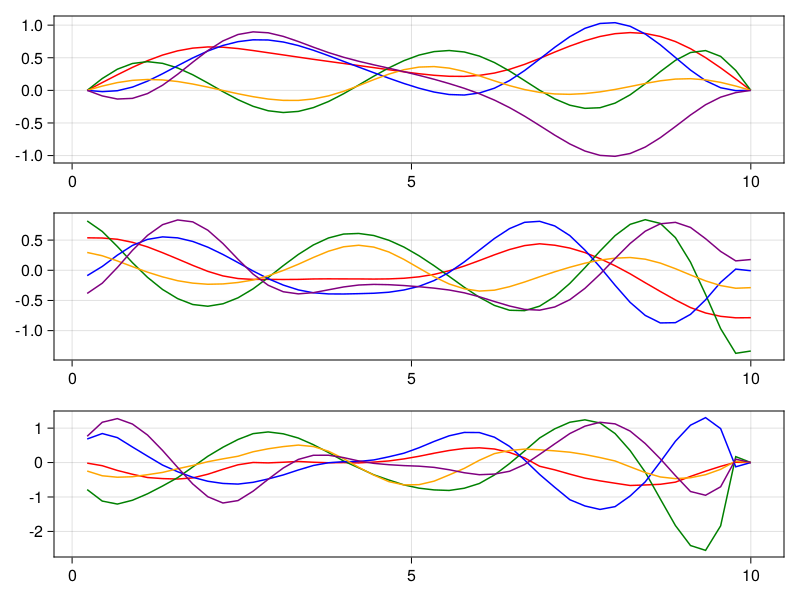

In [65]:
plot_control(rob_prob_4)

In [66]:
save("saved-pulses/single_qubit_gateset_R1e-6.jld2", rob_prob_4.trajectory)

In [67]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-6.csv", rob_prob_4.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, tightest constraint

In [68]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-2)
objective += QuadraticRegularizer(:a, trajectory, 1e-2)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_5 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

            memory estimate for stored jacobians: T * sizeof(∂f) = 45 * 0.003392208 = 0.15264935999999998 GB
applying constraint: initial value of Ũ⃗
applying constraint: initial value of a
applying constraint: final value of a
applying constraint: bounds on a
applying constraint: bounds on dda


QuantumControlProblem(Ipopt.Optimizer, MathOptInterface.VariableIndex[MOI.VariableIndex(1) MOI.VariableIndex(2064) … MOI.VariableIndex(88710) MOI.VariableIndex(90773); MOI.VariableIndex(2) MOI.VariableIndex(2065) … MOI.VariableIndex(88711) MOI.VariableIndex(90774); … ; MOI.VariableIndex(2062) MOI.VariableIndex(4125) … MOI.VariableIndex(90771) MOI.VariableIndex(92834); MOI.VariableIndex(2063) MOI.VariableIndex(4126) … MOI.VariableIndex(90772) MOI.VariableIndex(92835)], QuantumSystem{Float64}(sparse(Int64[], Int64[], Float64[], 32, 32), sparse(Int64[], Int64[], Float64[], 32, 32), SparseMatrixCSC{Float64, Int64}[sparse([17, 18, 19, 20, 21, 22, 23, 24, 25, 26  …  7, 8, 9, 10, 11, 12, 13, 14, 15, 16], [1, 2, 3, 4, 5, 6, 7, 8, 9, 10  …  23, 24, 25, 26, 27, 28, 29, 30, 31, 32], [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0  …  1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0], 32, 32), sparse([9, 10, 11, 12, 13, 14, 15, 16, 1, 2  …  31, 32, 17, 18, 19, 20, 21, 22, 23, 24], [1, 2, 3, 4, 5

In [69]:
solve!(rob_prob_5; max_iter=75)

println("Fidelity: ", unitary_fidelity(rob_prob_5))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_5))

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.6.1.

Number of nonzeros in equality constraint Jacobian...:  6143262
Number of nonzeros in inequality constraint Jacobian.:      256
Number of nonzeros in Lagrangian Hessian.............:        0

Total number of variables............................:    90777
                     variables with only lower bounds:        0
                variables with lower and upper bounds:        0
                     variables with only upper bounds:        0
Total number of equality constraints.................:    90552
Total number of inequality constraints...............:        1
        inequality constraints with only lower bounds:        1
   inequality constraints with lower and upper bounds:        0
        inequality constraints with only upper bounds:        0

iter    objective    inf_pr   inf_du lg(mu)  ||d||  lg(rg) alpha_du alpha_pr  ls
   0  9.9690215e-03 2.36e-04 3.88e-04   0.0 0.00e+00    -  0.00e+00 0.00e+00 

   1  9.9700673e-03 1.25e-03 2.14e-02  -4.0 1.15e-02    -  1.00e+00 8.63e-01h  1


   2  9.8645743e-03 1.10e-04 2.61e-03  -4.0 1.43e-01    -  1.00e+00 1.00e+00h  1


   3  9.7672442e-03 1.26e-04 7.44e-04  -4.0 1.80e-01    -  1.00e+00 1.00e+00h  1


   4  9.6338251e-03 8.58e-04 3.66e-03  -4.0 2.67e-01    -  1.00e+00 1.00e+00h  1


   5  9.6438382e-03 4.82e-04 2.15e-03  -4.0 1.59e-01    -  1.00e+00 1.00e+00h  1


... (66 outputs left out)

  73  9.6039351e-03 1.77e-05 7.52e-02  -6.6 1.77e-01    -  1.00e+00 9.77e-04h 10


  74  9.6039637e-03 1.76e-05 7.32e-02  -6.6 6.60e-01    -  1.00e+00 9.77e-04h 11


  75  9.6039722e-03 1.76e-05 6.94e-02  -6.6 3.70e-01    -  1.00e+00 1.95e-03h 10

Number of Iterations....: 75

                                   (scaled)                 (unscaled)
Objective...............:   9.6039721511866662e-03    9.6039721511866662e-03
Dual infeasibility......:   6.9358567099475993e-02    6.9358567099475993e-02
Constraint violation....:   1.7609315381639234e-05    1.7609315381639234e-05
Variable bound violation:   0.0000000000000000e+00    0.0000000000000000e+00
Complementarity.........:   2.2093425687988386e-07    2.2093425687988386e-07
Overall NLP error.......:   6.9358567099475993e-02    6.9358567099475993e-02


Number of objective function evaluations             = 565
Number of objective gradient evaluations             = 76
Number of equality constraint evaluations            = 566
Number of inequality constraint evaluations          = 566
Number of equality constraint Jacobian evaluations   = 77
Number of inequality constraint Jacobian evaluations = 77
Nu

0.002677089973978134


In [70]:
println("max(a): ", maximum(rob_prob_5.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_5.trajectory[:dda]))

max(a): 0.6200310053237138
max(dda): 0.1921462039934657


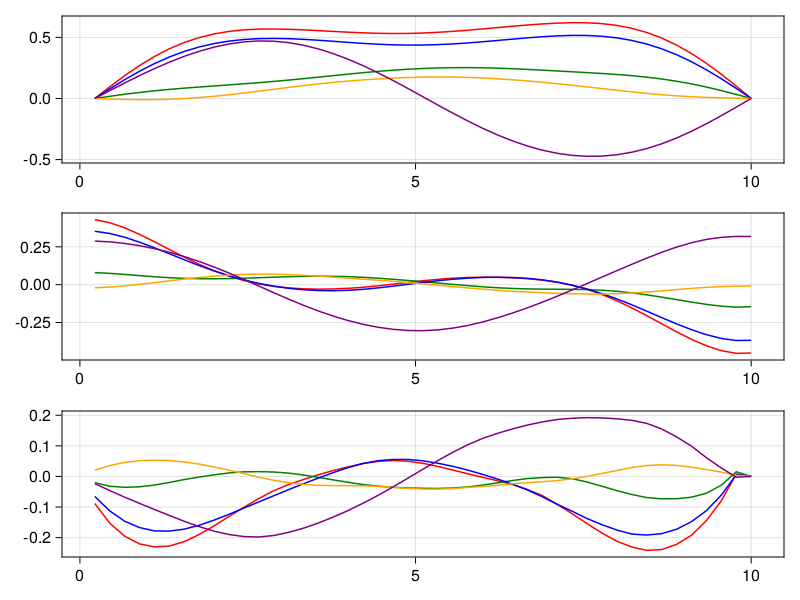

In [71]:
plot_control(rob_prob_5)

In [72]:
save("saved-pulses/single_qubit_gateset_R1e-2.jld2", rob_prob_5.trajectory)

In [73]:
writedlm("saved-pulses/a_single_qubit_gateset_R1e-2.csv", rob_prob_5.trajectory[:a], ",")

# From 1.0 bound gate, no constraint, max regularization

In [ ]:
trajectory = copy(rob_prob_1.trajectory)
parameters = deepcopy(prob.params)

objective = DefaultObjective()
objective += QuadraticRegularizer(:dda, trajectory, 1e-1)
objective += QuadraticRegularizer(:a, trajectory, 1e-1)

update_bound!(trajectory, :a, Inf)
update_bound!(trajectory, :dda, Inf)
constraints = trajectory_constraints(trajectory)

ipopt_options = Options()
ipopt_options.hessian_approximation = "limited-memory"
ipopt_options.recalc_y = "yes"
ipopt_options.recalc_y_feas_tol = 1e-2

rob_prob_6 = UnitaryRobustnessProblem(
    H_crosstalk,
    trajectory,
    prob.system,
    objective,
    prob.integrators,
    constraints;
    final_fidelity=0.9999,
    verbose=false,
    build_trajectory_constraints=false,
    hessian_approximation=true,
    ipopt_options=ipopt_options
)

In [ ]:
solve!(rob_prob_6; max_iter=50)

println("Fidelity: ", unitary_fidelity(rob_prob_6))
println("Robustness: ", infidelity_robustness(H_crosstalk, rob_prob_6))

In [ ]:
println("max(a): ", maximum(rob_prob_6.trajectory[:a]))
println("max(dda): ", maximum(rob_prob_6.trajectory[:dda]))

In [ ]:
plot_control(rob_prob_6)

In [ ]:
save("saved-pulses/single_qubit_gateset_R1e-1.jld2", rob_prob_6.trajectory)